In [55]:
import duckdb
con = duckdb.connect("../data/processed/agro.duckdb", read_only=True)

In [56]:
con.sql("""
SELECT period,
       ROUND(yield_t_ha, 2) AS yield_t_ha,
       ROUND(yield_t_ha - LAG(yield_t_ha) OVER (ORDER BY period), 2) AS change_vs_prev
FROM yields
WHERE region = 'Casanare'
  AND period >= '2008-I'
ORDER BY period
""").df()

,period,yield_t_ha,change_vs_prev
0,2008-I,6.08,NaN
1,2008-II,5.40,-0.68
2,2009-I,6.02,0.62
3,2009-II,5.11,-0.91
4,2010-I,5.36,0.24
5,2010-II,5.39,0.04
6,2011-I,5.06,-0.33
7,2011-II,4.26,-0.80
8,2012-I,4.89,0.64
9,2012-II,4.88,-0.01


El semestre I casi siempre sube frente al semestre II anterior, y el semestre II casi siempre baja frente al semestre I del mismo año (excepción: 2011-I bajó).

In [57]:
con.sql(""" SELECT period,
       ROUND(yield_t_ha, 2) AS yield_t_ha,
       ROUND(AVG(yield_t_ha) OVER (ORDER BY period ROWS BETWEEN 5 PRECEDING AND CURRENT ROW), 2) AS moving_avg_6
FROM yields
WHERE region = 'Casanare'
  AND period >= '2008-I'
ORDER BY period
""").df()

,period,yield_t_ha,moving_avg_6
0,2008-I,6.08,6.08
1,2008-II,5.40,5.74
2,2009-I,6.02,5.83
3,2009-II,5.11,5.65
4,2010-I,5.36,5.60
5,2010-II,5.39,5.56
6,2011-I,5.06,5.39
7,2011-II,4.26,5.20
8,2012-I,4.89,5.01
9,2012-II,4.88,4.97


In [58]:
con.sql("""
WITH casanare AS (
    SELECT period,
           split_part(period, '-', 2) AS semester,
           yield_t_ha
    FROM yields
    WHERE region = 'Casanare'
      AND period >= '2008-I'
)
SELECT semester,
       COUNT(*)                     AS semesters,
       ROUND(AVG(yield_t_ha), 2)    AS avg_yield,
       ROUND(STDDEV(yield_t_ha), 2) AS std_yield,
       ROUND(min(yield_t_ha), 2) AS min_yield,
       ROUND(max(yield_t_ha), 2) AS max_yield
FROM casanare
GROUP BY semester
ORDER BY semester
""").df()

,semester,semesters,avg_yield,std_yield,min_yield,max_yield
0,I,19,5.63,0.37,4.89,6.08
1,II,18,5.12,0.34,4.26,5.46


In [59]:
con.sql("""
WITH casanare AS (
    SELECT period,
           split_part(period, '-', 2) AS semester,
           yield_t_ha
    FROM yields
    WHERE region = 'Casanare'
      AND period >= '2008-I'
)
SELECT period,
       semester,
       ROUND(yield_t_ha, 2) AS yield_t_ha,
       ROUND(yield_t_ha - LAG(yield_t_ha) OVER (ORDER BY period), 2) AS change_vs_prev,
       ROUND(yield_t_ha - LAG(yield_t_ha) OVER (PARTITION BY semester ORDER BY period), 2) AS change_vs_last_year
FROM casanare
ORDER BY period
""").df()


,period,semester,yield_t_ha,change_vs_prev,change_vs_last_year
0,2008-I,I,6.08,NaN,NaN
1,2008-II,II,5.40,-0.68,NaN
2,2009-I,I,6.02,0.62,-0.06
3,2009-II,II,5.11,-0.91,-0.29
4,2010-I,I,5.36,0.24,-0.66
5,2010-II,II,5.39,0.04,0.28
6,2011-I,I,5.06,-0.33,-0.30
7,2011-II,II,4.26,-0.80,-1.14
8,2012-I,I,4.89,0.64,-0.17
9,2012-II,II,4.88,-0.01,0.63


In [60]:
con.sql("""
WITH casanare AS (
    SELECT period,
           split_part(period, '-', 2) AS semester,
           yield_t_ha
    FROM yields
    WHERE region = 'Casanare'
      AND period >= '2008-I'
)
SELECT period,
       semester,
       ROUND(yield_t_ha, 2) AS yield_t_ha,
       ROUND(yield_t_ha / AVG(yield_t_ha) OVER (), 3)                      AS ratio_all,
       ROUND(yield_t_ha / AVG(yield_t_ha) OVER (PARTITION BY semester), 3) AS ratio_own_semester
FROM casanare
ORDER BY ratio_all""").df()

,period,semester,yield_t_ha,ratio_all,ratio_own_semester
0,2011-II,II,4.26,0.790,0.831
1,2013-II,II,4.54,0.844,0.887
2,2017-II,II,4.67,0.867,0.911
3,2012-II,II,4.88,0.907,0.953
4,2012-I,I,4.89,0.909,0.869
5,2015-II,II,5.00,0.929,0.976
6,2011-I,I,5.06,0.940,0.899
7,2013-I,I,5.07,0.941,0.900
8,2009-II,II,5.11,0.950,0.998
9,2023-II,II,5.15,0.956,1.005


### Hallazgos

1. El semestre I rinde más que el semestre II: 5,63 contra 5,12 t/ha en promedio, cerca de 9% menos en el semestre II. Comparar cada semestre con el anterior mezcla esa diferencia de temporada con las pérdidas reales, así que los semestres I y II se analizan por separado.
2. Frente al promedio general, 2011-II y 2013-II quedan por debajo del 85%. Frente al promedio de los semestres II, solo 2011-II: 2013-II parecía un semestre malo solo por ser semestre II.

## Sesión 2 · Tendencia

In [61]:
import numpy as np
import matplotlib.pyplot as plt

df = con.sql("""
SELECT period,
       CAST(split_part(period, '-', 1) AS INTEGER) AS year,
       split_part(period, '-', 2)                  AS semester,
       yield_t_ha
FROM yields
WHERE region = 'Casanare'
  AND period >= '2008-I'
ORDER BY period
""").df()
df.head()

,period,year,semester,yield_t_ha
0,2008-I,2008,I,6.084696
1,2008-II,2008,II,5.400000
2,2009-I,2009,I,6.020000
3,2009-II,2009,II,5.114849
4,2010-I,2010,I,5.356509


In [62]:
sem_i = df[df["semester"] == "I"]
slope, intercept = np.polyfit(sem_i["year"], sem_i["yield_t_ha"], deg=1)
print(slope, intercept)

0.009558635682447202 -13.650682461730796


In [63]:
sem_ii = df[df["semester"] == "II"]
slope, intercept = np.polyfit(sem_ii["year"], sem_ii["yield_t_ha"], deg=1)
print(slope, intercept)

0.019720669614737042 -34.643728424380726


In [64]:
DEGREE = 1

df["trend"] = np.nan
for sem in ["I", "II"]:
    rows = df["semester"] == sem
    coefs = np.polyfit(df.loc[rows, "year"], df.loc[rows, "yield_t_ha"], deg=DEGREE)
    df.loc[rows, "trend"] = np.polyval(coefs, df.loc[rows, "year"])
df

,period,year,semester,yield_t_ha,trend
0,2008-I,2008,I,6.084696,5.543058
1,2008-II,2008,II,5.400000,4.955376
2,2009-I,2009,I,6.020000,5.552617
3,2009-II,2009,II,5.114849,4.975097
4,2010-I,2010,I,5.356509,5.562175
5,2010-II,2010,II,5.391826,4.994818
6,2011-I,2011,I,5.060118,5.571734
7,2011-II,2011,II,4.255126,5.014538
8,2012-I,2012,I,4.894344,5.581293
9,2012-II,2012,II,4.882266,5.034259


In [65]:
df["deviation"] = df["yield_t_ha"] / df["trend"] - 1
df.sort_values("deviation").head(5)

,period,year,semester,yield_t_ha,trend,deviation
7,2011-II,2011,II,4.255126,5.014538,-0.151442
8,2012-I,2012,I,4.894344,5.581293,-0.123081
11,2013-II,2013,II,4.543953,5.053980,-0.100916
10,2013-I,2013,I,5.066851,5.590851,-0.093725
6,2011-I,2011,I,5.060118,5.571734,-0.091823


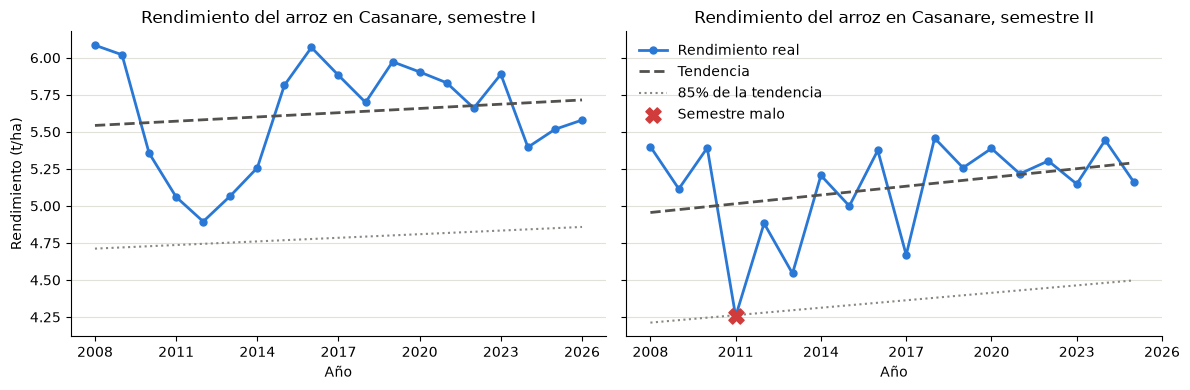

In [66]:
COLORS = {"actual": "#2a78d6", "trend": "#52514e", "threshold": "#898781", "bad": "#d03b3b"}
THRESHOLD = 0.85  # semestre malo = rendimiento por debajo del 85% de la tendencia

fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharey=True)
for ax, sem in zip(axes, ["I", "II"]):
    d = df[df["semester"] == sem]
    bad = d[d["yield_t_ha"] < THRESHOLD * d["trend"]]
    ax.plot(d["year"], d["yield_t_ha"], color=COLORS["actual"], linewidth=2,
            marker="o", markersize=5, label="Rendimiento real")
    ax.plot(d["year"], d["trend"], color=COLORS["trend"], linewidth=2,
            linestyle="--", label="Tendencia")
    ax.plot(d["year"], THRESHOLD * d["trend"], color=COLORS["threshold"], linewidth=1.5,
            linestyle=":", label=f"{THRESHOLD:.0%} de la tendencia")
    ax.scatter(bad["year"], bad["yield_t_ha"], color=COLORS["bad"], marker="X", s=120,
               zorder=3, label="Semestre malo")
    ax.set_title(f"Rendimiento del arroz en Casanare, semestre {sem}")
    ax.set_xlabel("Año")
    ax.set_xticks(range(2008, 2027, 3))
    ax.grid(axis="y", color="#e1e0d9", linewidth=0.8)
    ax.spines[["top", "right"]].set_visible(False)
axes[0].set_ylabel("Rendimiento (t/ha)")
axes[1].legend(loc="upper left", frameon=False)
plt.tight_layout()
plt.show()

### Hallazgos

1. La tendencia es casi plana: el rendimiento del semestre I sube cerca de 0,01 t/ha por año (menos de 2% por década) y el del semestre II cerca de 0,02 t/ha por año. Una tendencia cuadrática da casi los mismos desvíos (2012-I: −12,3% en ambos casos), así que se mantiene la tendencia lineal.
2. Solo un semestre, 2011-II (−15,1%), cae por debajo del 85% de su tendencia. Los promedios del departamento compensan las pérdidas de cada finca, así que una finca sola probablemente tiene más riesgo del que muestran estos datos.
3. Los tres peores semestres (2011-II, 2012-I y 2013-II) son seguidos: los años malos vienen en racha, así que hay que revisar la independencia entre semestres antes de simular.

## Sesión 3 · Umbral

In [67]:
%load_ext autoreload
%autoreload 2
import sys
sys.path.append("..")
from src.risk import detrend

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [68]:
detrended = detrend(df)
df

,period,year,semester,yield_t_ha,trend,deviation
0,2008-I,2008,I,6.084696,5.543058,0.097715
1,2008-II,2008,II,5.400000,4.955376,0.089726
2,2009-I,2009,I,6.020000,5.552617,0.084174
3,2009-II,2009,II,5.114849,4.975097,0.028090
4,2010-I,2010,I,5.356509,5.562175,-0.036976
5,2010-II,2010,II,5.391826,4.994818,0.079484
6,2011-I,2011,I,5.060118,5.571734,-0.091823
7,2011-II,2011,II,4.255126,5.014538,-0.151442
8,2012-I,2012,I,4.894344,5.581293,-0.123081
9,2012-II,2012,II,4.882266,5.034259,-0.030192


In [69]:
detrend(df, by=None)

,period,year,semester,yield_t_ha,trend,deviation
0,2008-I,2008,I,6.084696,5.239186,0.161382
1,2008-II,2008,II,5.400000,5.239186,0.030694
2,2009-I,2009,I,6.020000,5.255596,0.145446
3,2009-II,2009,II,5.114849,5.255596,-0.026780
4,2010-I,2010,I,5.356509,5.272006,0.016029
5,2010-II,2010,II,5.391826,5.272006,0.022728
6,2011-I,2011,I,5.060118,5.288416,-0.043169
7,2011-II,2011,II,4.255126,5.288416,-0.195387
8,2012-I,2012,I,4.894344,5.304826,-0.077379
9,2012-II,2012,II,4.882266,5.304826,-0.079656


In [70]:
import pandas as pd

rows = []
for u in [0.80, 0.85, 0.90]:
    bad = detrended[detrended["deviation"] < u - 1]
    rows.append({"threshold": u, "bad_semesters": len(bad), "periods": ", ".join(bad["period"])})
thresholds = pd.DataFrame(rows)
thresholds

,threshold,bad_semesters,periods
0,0.80,0,
1,0.85,1,2011-II
2,0.90,3,"2011-II, 2012-I, 2013-II"


In [71]:
thresholds = pd.DataFrame(rows)
thresholds["frequency"] = thresholds["bad_semesters"] / len(detrended)
thresholds

,threshold,bad_semesters,periods,frequency
0,0.80,0,,0.000000
1,0.85,1,2011-II,0.027027
2,0.90,3,"2011-II, 2012-I, 2013-II",0.081081
